# Módulo 3 — Teoría y demostraciones

Notebook de apoyo para la teoría del **Día 4** (ver [`README.md`](../README.md)).

> **Nota sobre los datos usados:** este módulo usa descargas **reales**,
> no simuladas — `cdsapi` (ERA5), `Herbie` (GFS) y `wget`/`tcsh` (FNL, vía
> GDEX/NCAR) con las credenciales reales del entorno del curso (FNL no
> necesita ninguna), recortadas a un dominio pequeño (Perú,
> `[0, -82, -18, -68]`) para que la descarga sea rápida y liviana. Esto es
> justo el tipo de recorte que se practica en el Módulo 2.
>
> La cuarta fuente, **SENAMHI**, no es un modelo sino mediciones de
> estaciones (Sección 3c). Sus archivos ya vienen descargados en
> `data/senamhi/`.

## Sección 1 — Reanálisis vs. pronóstico operativo

In [1]:
import pandas as pd

comparacion = pd.DataFrame({
    "ERA5 (reanálisis)": [
        "Retrospectivo (pasado)",
        "Modelo + asimilación de observaciones",
        "Consistente en todo el registro histórico",
        "Estudios de clima, forzar casos ya ocurridos",
    ],
    "GFS (pronóstico operativo)": [
        "Prospectivo (futuro, desde el ciclo de emisión)",
        "Solo modelo, corrido 4 veces al día (00/06/12/18 UTC)",
        "Cambia con el tiempo (resolución, versión del modelo)",
        "Simular un evento próximo, replicar un pronóstico real",
    ],
}, index=["Naturaleza del dato", "Cómo se genera", "Consistencia temporal", "Caso de uso típico"])

comparacion

,ERA5 (reanálisis),GFS (pronóstico operativo)
Naturaleza del dato,Retrospectivo (pasado),"Prospectivo (futuro, desde el ciclo de emisión)"
Cómo se genera,Modelo + asimilación de observaciones,"Solo modelo, corrido 4 veces al día (00/06/12/..."
Consistencia temporal,Consistente en todo el registro histórico,"Cambia con el tiempo (resolución, versión del ..."
Caso de uso típico,"Estudios de clima, forzar casos ya ocurridos","Simular un evento próximo, replicar un pronóst..."


## Sección 2 — cdsapi: solicitud real a Copernicus CDS

Solicitud real de ERA5 (1 variable, 1 día, 4 horas, dominio pequeño de
Perú) usando las credenciales de `~/.cdsapirc`. Se guarda en caché local:
si el archivo ya existe, no se vuelve a pedir al servidor — el CDS procesa
por cola (Sección 3 de la teoría del README) y no tiene sentido repetir la
espera en cada corrida del notebook.

In [2]:
import os
import cdsapi

def descargar_era5(fecha, area, variables, horas, destino):
    """Descarga real de ERA5 vía cdsapi. area=[norte, oeste, sur, este]."""
    if os.path.exists(destino):
        print(f"Ya existe {destino}, no se vuelve a pedir al servidor.")
        return destino
    anio, mes, dia = fecha.split("-")
    client = cdsapi.Client()
    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": "reanalysis",
            "variable": variables,
            "year": anio, "month": mes, "day": dia,
            "time": horas,
            "area": area,
            "format": "netcdf",
        },
        destino,
    )
    return destino

archivo_era5 = descargar_era5(
    fecha="2025-03-15", area=[0, -82, -18, -68],
    variables=["2m_temperature"], horas=["00:00", "06:00", "12:00", "18:00"],
    destino="demo_era5_real.nc",
)
print("Archivo real descargado:", archivo_era5)

Ya existe demo_era5_real.nc, no se vuelve a pedir al servidor.
Archivo real descargado: demo_era5_real.nc


/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


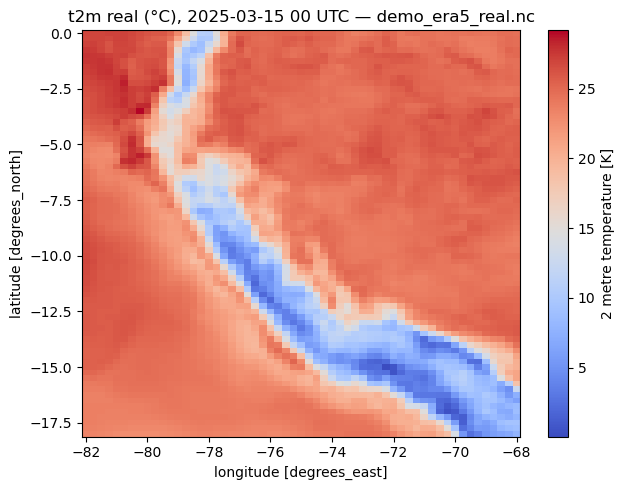

In [3]:
import xarray as xr
import matplotlib.pyplot as plt

ds_era5_demo = xr.open_dataset(archivo_era5)
fig, ax = plt.subplots(figsize=(6.5, 5))
(ds_era5_demo["t2m"].isel(valid_time=0) - 273.15).plot(ax=ax, cmap="coolwarm")
ax.set_title(f"t2m real (°C), 2025-03-15 00 UTC — {archivo_era5}")
fig.tight_layout()
plt.show()

## Sección 3 — Herbie: descarga real de GFS

Descarga real de GFS con Herbie. **Gotcha real, no hipotético:** pedir un
ciclo muy reciente puede colgarse buscando en NOMADS (el servidor
operativo, con retención corta y a veces lento); usando una fecha ya
archivada (semanas atrás) y una prioridad explícita de fuente
(`priority=["aws", "google"]`) la búsqueda va directo al archivo histórico
en la nube y responde de inmediato. Herbie descarga solo el mensaje GRIB2
de la variable pedida (no el archivo global completo) gracias al índice
`.idx` — por eso el archivo resultante es liviano (unos MB) aunque cubra
todo el planeta; recién después se recorta al dominio pequeño con
`.sel()`, igual que en el Módulo 2.

In [4]:
from herbie import Herbie

h = Herbie("2025-03-15 00:00", model="gfs", product="pgrb2.0p25", fxx=0,
           priority=["aws", "google"])
ds_gfs_global = h.xarray(":TMP:2 m above ground")
print("Descarga real completada. Forma global:", dict(ds_gfs_global.sizes))

lon_oeste, lon_este = -82 % 360, -68 % 360  # convención GFS 0-360 (Módulo 2)
ds_gfs_demo = ds_gfs_global.sel(latitude=slice(0, -18), longitude=slice(lon_oeste, lon_este))
print("Recortado a Perú:", dict(ds_gfs_demo.sizes))

✅ Found ┊ model=gfs ┊ product=pgrb2.0p25 ┊ 2025-Mar-15 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local


/home/japq/.conda/envs/jap/lib/python3.13/site-packages/herbie/core.py:1280: UserWarning: Will not remove GRIB file because it previously existed.
  warnings.warn("Will not remove GRIB file because it previously existed.")


Descarga real completada. Forma global: {'latitude': 721, 'longitude': 1440}
Recortado a Perú: {'latitude': 73, 'longitude': 57}


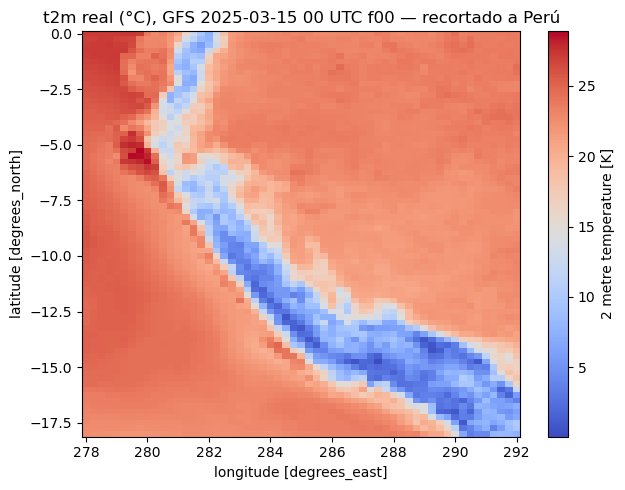

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5))
(ds_gfs_demo["t2m"] - 273.15).plot(ax=ax, cmap="coolwarm")
ax.set_title("t2m real (°C), GFS 2025-03-15 00 UTC f00 — recortado a Perú")
fig.tight_layout()
plt.show()

## Sección 3b — FNL: descarga real por HTTPS directo (GDEX/NCAR)

A diferencia de Herbie y `cdsapi`, que son librerías de Python que abstraen
el repositorio remoto, FNL (`d083003` en GDEX/NCAR) se distribuye como
archivos planos por HTTPS directo, **sin cuenta ni autenticación**: la URL
sigue un patrón predecible por fecha, y basta un `wget` por cada paso de
pronóstico del ciclo. El curso trae un script `csh` ya parametrizado por
fecha (`data/descarga_FNL.csh`, uso: `tcsh descarga_FNL.csh AAAAMMDD`) —
automatizar una descarga no siempre significa que exista un paquete de
Python para ello.

Los archivos de este notebook ya fueron descargados con ese script para el
ciclo **2025-03-15 00 UTC** (mismo mes que las observaciones reales de las
estaciones de Perú usadas en el Módulo 5) y quedaron en `unalm/data/`. Se
abren aquí igual que cualquier GRIB2 real del Módulo 2, filtrando por
`typeOfLevel` porque un FNL trae varios niveles en el mismo archivo.

In [6]:
import os

RUTA_DATOS = "../../../data"  # unalm/data, compartida por todo el curso
archivo_fnl = os.path.join(RUTA_DATOS, "gdas1.fnl0p25.2025031500.f00.grib2")

ds_fnl_global = xr.open_dataset(
    archivo_fnl, engine="cfgrib",
    backend_kwargs={"filter_by_keys": {"typeOfLevel": "heightAboveGround", "level": 2}},
)
print("Descarga real (ya realizada con descarga_FNL.csh). Forma global:", dict(ds_fnl_global.sizes))
print("Valid time:", str(ds_fnl_global.valid_time.values))

ds_fnl_demo = ds_fnl_global.sel(latitude=slice(0, -18), longitude=slice(lon_oeste, lon_este))
print("Recortado a Perú:", dict(ds_fnl_demo.sizes))

Ignoring index file '../../../data/gdas1.fnl0p25.2025031500.f00.grib2.da267.idx' incompatible with GRIB file


Descarga real (ya realizada con descarga_FNL.csh). Forma global: {'latitude': 721, 'longitude': 1440}
Valid time: 2025-03-15T00:00:00.000000000
Recortado a Perú: {'latitude': 73, 'longitude': 57}


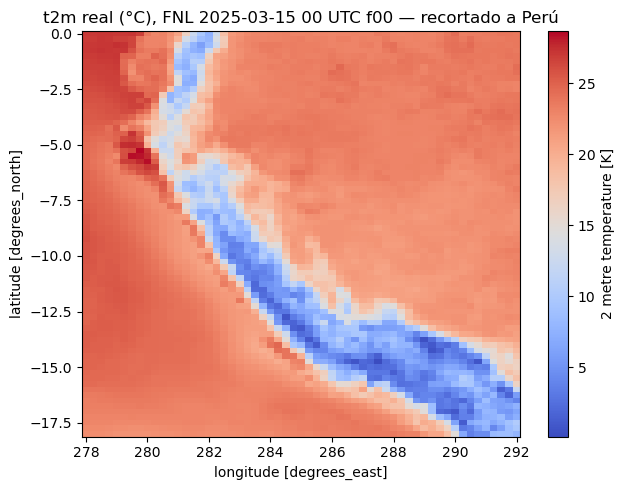

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
(ds_fnl_demo["t2m"] - 273.15).plot(ax=ax, cmap="coolwarm")
ax.set_title("t2m real (°C), FNL 2025-03-15 00 UTC f00 — recortado a Perú")
fig.tight_layout()
plt.show()

## Sección 3c — SENAMHI: observaciones de estaciones (demostración del docente)

Las tres fuentes anteriores son **modelos**: grillas que cubren todo el
planeta y que el WRF usa como entrada. SENAMHI es otra cosa: **mediciones**
de estaciones meteorológicas, en puntos concretos. No entran al WRF: sirven
para comprobar si lo que el WRF simuló se parece a lo que de verdad pasó
(Módulos 5 y 6).

**Cómo se obtienen.** El portal «Mapa de estaciones» de SENAMHI pide pasar
una verificación de Cloudflare (la casilla de «no soy un robot») para cada
descarga. Esa verificación existe justamente para que ningún programa
descargue solo, así que **siempre hay una persona en el medio**: el docente
usa la herramienta [`station-hist`](https://github.com/Japq91/station-hist),
que abre el navegador, espera a que la persona pase la verificación y
después baja y arma el CSV:

```bash
# 1. Buscar el código (no abre el navegador)
python run_operativo.py --search "CAMPO DE MARTE"
#   112171  Campo De Marte  -> convencional (lecturas a horas fijas)
#   112181  Campo De Marte  -> automática (cada hora)  <- la que usamos

# 2. Descargar un año: se abre el navegador; si aparece la casilla, se marca
python run_operativo.py --station 112181 --yeari 2025 --yearf 2025
#   OK -> downloads_operativo/112181-2025-2025.csv
```

El archivo trae el año completo; para el curso se recortó solo marzo. El
paso a paso (instalación, varias estaciones, recorte y qué revisar) está en
`data/senamhi/README.md`.

La lección: automatizar no siempre significa sacar a la persona del
proceso. Se automatiza todo lo demás, y se respeta lo que el sitio pide
hacer a mano.

Los archivos de 5 estaciones de Lima (marzo de 2025) ya están en
`data/senamhi/`. Así se ve uno por dentro:

In [8]:
import pandas as pd

RUTA_SENAMHI = "../../../data/senamhi/"
crudo = pd.read_csv(RUTA_SENAMHI + "112181_2025_03.csv", sep=";", dtype=str)   # Campo de Marte, Lima
print("Columnas:", list(crudo.columns))
crudo.head()

Columnas: ['Año', 'Mes', 'Día', 'Hora', 'Temperatura (°C)', 'Precipitación (mm)', 'Humedad (%)', 'Dir. Viento (°)', 'Vel. Viento (m/s)']


,Año,Mes,Día,Hora,Temperatura (°C),Precipitación (mm),Humedad (%),Dir. Viento (°),Vel. Viento (m/s)
0,2025,03,01,00:00,22.6,0.0,87,236,1.1
1,2025,03,01,01:00,22.3,0.0,88,237,0.8
2,2025,03,01,02:00,22.1,0.0,89,217,0.3
3,2025,03,01,03:00,21.8,0.0,91,232,0.3
4,2025,03,01,04:00,21.7,0.0,91,215,0.8


**En qué se diferencia de las otras tres fuentes:**

| | ERA5 / GFS / FNL | SENAMHI |
|---|---|---|
| Qué es | Modelo: un valor por celda de grilla | Medición en un punto (la estación) |
| Formato | NetCDF o GRIB2 | Texto CSV separado por `;` |
| Hora | UTC | **Local de Perú (UTC−5)** |
| Datos que faltan | Casi nunca | Frecuentes: `S/D` («sin dato») u horas que no están |
| Cómo se descarga | Programa solo (cdsapi, Herbie, wget) | Persona + programa (verificación en el navegador) |

## Sección 4 — Comparar las tres fuentes con lo que midió la estación

Con datos 100% reales de tres fuentes distintas, mismo instante
(**2025-03-15 00 UTC** — el mismo ciclo para las tres, y el mismo mes que
las observaciones reales de estaciones de Perú del Módulo 5) y mismo
dominio, ya se puede hacer una comparación real simple. Y ahora tenemos
con qué compararlas: lo que midió la estación Campo de Marte, a unos 2 km
del punto — un preview de lo
que el Módulo 5 hace con rigor.

In [9]:
lat_punto, lon_punto = -12.05, -77.04  # Lima

t2m_era5_punto = float(ds_era5_demo["t2m"].isel(valid_time=0).sel(
    latitude=lat_punto, longitude=lon_punto, method="nearest")) - 273.15
t2m_gfs_punto = float(ds_gfs_demo.sel(
    latitude=lat_punto, longitude=lon_punto % 360, method="nearest")["t2m"]) - 273.15
t2m_fnl_punto = float(ds_fnl_demo.sel(
    latitude=lat_punto, longitude=lon_punto % 360, method="nearest")["t2m"]) - 273.15

print(f"ERA5 (reanálisis) en Lima, 2025-03-15 00 UTC: {t2m_era5_punto:.2f} °C")
print(f"GFS  (pronóstico)  en Lima, 2025-03-15 00 UTC: {t2m_gfs_punto:.2f} °C")
print(f"FNL  (análisis)    en Lima, 2025-03-15 00 UTC: {t2m_fnl_punto:.2f} °C")
print()
print(f"Diferencia ERA5 vs. GFS: {abs(t2m_era5_punto - t2m_gfs_punto):.2f} °C")
print(f"Diferencia ERA5 vs. FNL: {abs(t2m_era5_punto - t2m_fnl_punto):.2f} °C")
print(f"Diferencia GFS  vs. FNL: {abs(t2m_gfs_punto - t2m_fnl_punto):.2f} °C")
print()

# SENAMHI usa hora local (UTC-5): las 00 UTC del 15 son las 19:00 del 14 en Lima
fila = crudo[(crudo["Día"] == "14") & (crudo["Hora"] == "19:00")]
t2m_obs = float(fila["Temperatura (°C)"].iloc[0])
print(f"SENAMHI (medido)   en Campo de Marte, 19:00 hora local: {t2m_obs:.2f} °C")
for nombre, valor in [("ERA5", t2m_era5_punto), ("GFS ", t2m_gfs_punto), ("FNL ", t2m_fnl_punto)]:
    print(f"  {nombre} - medido: {valor - t2m_obs:+.2f} °C")
print()
print("Las tres fuentes describen el mismo instante real con tres sistemas",
      "distintos (reanalisis, pronostico, y analisis reprocesado) -- estas",
      "diferencias NO son errores, son la variabilidad esperable entre",
      "ellas. FNL y GFS comparten origen (NCEP) y suelen ser mas parecidos",
      "entre si que cualquiera de los dos frente a ERA5 (ECMWF/Copernicus).")
print()
print("La estacion recuerda que ninguna de las tres es 'la verdad': cada una da",
      "un valor para una celda de unos 25 km, y el sensor mide en un solo punto.")

ERA5 (reanálisis) en Lima, 2025-03-15 00 UTC: 22.26 °C
GFS  (pronóstico)  en Lima, 2025-03-15 00 UTC: 23.99 °C
FNL  (análisis)    en Lima, 2025-03-15 00 UTC: 23.70 °C

Diferencia ERA5 vs. GFS: 1.73 °C
Diferencia ERA5 vs. FNL: 1.44 °C
Diferencia GFS  vs. FNL: 0.29 °C

SENAMHI (medido)   en Campo de Marte, 19:00 hora local: 21.40 °C
  ERA5 - medido: +0.86 °C
  GFS  - medido: +2.59 °C
  FNL  - medido: +2.30 °C

Las tres fuentes describen el mismo instante real con tres sistemas distintos (reanalisis, pronostico, y analisis reprocesado) -- estas diferencias NO son errores, son la variabilidad esperable entre ellas. FNL y GFS comparten origen (NCEP) y suelen ser mas parecidos entre si que cualquiera de los dos frente a ERA5 (ECMWF/Copernicus).

La estacion recuerda que ninguna de las tres es 'la verdad': cada una da un valor para una celda de unos 25 km, y el sensor mide en un solo punto.


## Sección 5 — Lo que el WRF realmente necesita: el Vtable

Todo lo anterior descargó 1-2 variables por fuente, para aprender la
mecánica de cada API. Un WRF real necesita **mucho más**: `ungrib.exe`
(parte de WPS) usa una tabla llamada **Vtable** que lista exactamente qué
campos GRIB debe extraer y cómo renombrarlos. Sin todos esos campos,
`metgrid`/`real.exe` fallan o producen una simulación incompleta. Estos son
los Vtable **reales** de este curso (`unalm/data/Vtable.GFS`,
`Vtable.GDAS`, `Vtable.ERA5`) — el segundo generado a mano por el equipo
del curso a partir de este mismo archivo FNL.

In [10]:
RUTA_DATOS = "../../../data"

with open(f"{RUTA_DATOS}/Vtable.GFS") as f:
    vtable_gfs_txt = f.read()
with open(f"{RUTA_DATOS}/Vtable.GDAS") as f:
    vtable_gdas_txt = f.read()
with open(f"{RUTA_DATOS}/Vtable.ERA5") as f:
    vtable_era5_txt = f.read()

import re

def nombres_metgrid(texto):
    """Extrae la columna 'metgrid Name' de un archivo Vtable real."""
    nombres = []
    for linea in texto.splitlines():
        m = re.match(r"^[\s\d\*]*\|[\s\d\*]*\|[\s\d\*]*\|[\s\d\*]*\|\s*(\S+)\s*\|", linea)
        if m:
            nombres.append(m.group(1))
    return nombres

campos_gfs = nombres_metgrid(vtable_gfs_txt)
campos_gdas = nombres_metgrid(vtable_gdas_txt)
campos_era5 = nombres_metgrid(vtable_era5_txt)

print(f"Vtable.GFS  pide {len(campos_gfs)} campos")
print(f"Vtable.GDAS pide {len(campos_gdas)} campos")
print(f"Vtable.ERA5 pide {len(campos_era5)} campos")
print()
print("GFS y GDAS (FNL) piden EXACTAMENTE los mismos campos:",
      set(campos_gfs) == set(campos_gdas))
print("  En GFS pero no en GDAS:", sorted(set(campos_gfs) - set(campos_gdas)))
print("  En GDAS pero no en GFS:", sorted(set(campos_gdas) - set(campos_gfs)))
print()
print("Campos en GFS/GDAS que ERA5 NO pide igual:",
      sorted(set(campos_gfs) - set(campos_era5)))
print("Campos que solo pide ERA5:", sorted(set(campos_era5) - set(campos_gfs)))

Vtable.GFS  pide 44 campos
Vtable.GDAS pide 43 campos
Vtable.ERA5 pide 28 campos

GFS y GDAS (FNL) piden EXACTAMENTE los mismos campos: False
  En GFS pero no en GDAS: ['LANDN']
  En GDAS pero no en GFS: []

Campos en GFS/GDAS que ERA5 NO pide igual: ['HGT', 'HGTMAXW', 'HGTTROP', 'LANDN', 'PMAXW', 'PMAXWNN', 'PTROP', 'PTROPNN', 'SM000010', 'SM010040', 'SM010200', 'SM040100', 'SM100200', 'SNOWH', 'ST000010', 'ST010040', 'ST010200', 'ST040100', 'ST100200', 'TMAXW', 'TTROP', 'UMAXW', 'UTROP', 'VMAXW', 'VTROP']
Campos que solo pide ERA5: ['DEWPT', 'LOGSFP', 'PSFCH', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW_EC', 'SOILGEO', 'SPECHUMD', 'ST000007', 'ST007028', 'ST028100', 'ST100289']


**Por qué difieren.** GFS y FNL vienen del mismo centro (NCEP) con el mismo
formato, así que `Vtable.GDAS` (el que se armó a mano para FNL) pide
**casi** los mismos campos que `Vtable.GFS` — la única diferencia real es
`LANDN`, un campo de máscara tierra/mar más nuevo (agregado a GFS recién en
2017) que no se incluyó al armar `Vtable.GDAS` a mano; no es un problema,
porque `Vtable.GFS` mismo declara `LANDSEA` como alternativa si `LANDN` no
está disponible. ERA5 (ECMWF/Copernicus) es un sistema distinto, con
convenciones propias:
- Pide **humedad específica** (`SPECHUMD`) en vez de humedad relativa
  (`RH`) en los niveles de presión.
- Sus 4 capas de suelo tienen **otros límites** (0-7, 7-28, 28-100,
  100-289 cm) en vez de los de NCEP (0-10, 10-40, 40-100, 100-200 cm).
- Este `Vtable.ERA5` en particular está escrito para los archivos
  **nativos de ECMWF por niveles híbridos** (usa `LOGSFP`, presión de
  superficie logarítmica, típica de acceso directo a MARS) — **no** para
  el producto `reanalysis-era5-pressure-levels` que se pide por `cdsapi`
  en este curso. Ese producto ya viene interpolado a niveles de presión
  fijos, así que en vez de `LOGSFP` hace falta pedir **geopotencial**
  (`z`) explícito en cada nivel — es el mismo dato físico que `HGT` en
  GFS, solo que sin convertir de m²/s² a metros.

## Sección 6 — ¿Estos son los mismos datos que pide GDEX?

Sí: **GFS y FNL piden exactamente el mismo conjunto físico de variables**
(mismo Vtable). Se verifica en el archivo FNL real ya descargado que las 33
variables de niveles de presión y los grupos de superficie/suelo que pide
`Vtable.GDAS` existen de verdad — reproduciendo, esta vez con éxito, la
verificación que se intentó antes con la comparación cruda de discipline/
category/param (que dio 0% porque cfgrib no expone esos códigos GRIB1
directamente; hay que comparar por grupo `typeOfLevel` + `shortName`).

In [11]:
import cfgrib

archivo_fnl_completo = f"{RUTA_DATOS}/gdas1.fnl0p25.2025031500.f00.grib2"
grupos_fnl = cfgrib.open_datasets(archivo_fnl_completo)

# Grupos que pide Vtable.GDAS, identificados por typeOfLevel (Sección 3b/Módulo 2)
requeridos = {
    "isobaricInhPa (T,U,V,RH,HGT)": ["t", "u", "v", "r", "gh"],
    "heightAboveGround=2 (T,RH)":   ["t2m", "r2"],
    "heightAboveGround=10 (U,V)":   ["u10", "v10"],
    "meanSea (PMSL)":               ["mslet", "prmsl"],
    "depthBelowLandLayer (suelo)":  ["st", "soilw"],
    "surface (PSFC,LANDSEA,...)":   ["sp", "lsm", "siconc", "orog", "sdwe", "sde"],
}

for descripcion, esperados in requeridos.items():
    encontrados = set()
    for ds in grupos_fnl:
        encontrados |= (set(ds.data_vars) & set(esperados))
    faltan = set(esperados) - encontrados
    estado = "OK" if not faltan else f"FALTAN: {sorted(faltan)}"
    print(f"{descripcion:32s} -> {sorted(encontrados)} [{estado}]")

isobaricInhPa (T,U,V,RH,HGT)     -> ['gh', 'r', 't', 'u', 'v'] [OK]
heightAboveGround=2 (T,RH)       -> ['r2', 't2m'] [OK]
heightAboveGround=10 (U,V)       -> ['u10', 'v10'] [OK]
meanSea (PMSL)                   -> ['mslet', 'prmsl'] [OK]
depthBelowLandLayer (suelo)      -> ['soilw', 'st'] [OK]
surface (PSFC,LANDSEA,...)       -> ['lsm', 'orog', 'sde', 'sdwe', 'siconc', 'sp'] [OK]


/home/japq/.conda/envs/jap/lib/python3.13/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
/home/japq/.conda/envs/jap/lib/python3.13/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
/home/japq/.co

**Herbie (GFS) trae lo mismo, on-demand.** No hace falta un archivo
completo: un solo `searchString` con expresión regular trae los 33 niveles
de presión de una variable en un solo pedido.

In [ ]:
ds_gfs_perfil = h.xarray(":TMP:\\d+ mb")  # los 33 niveles de temperatura, un solo pedido
print("Niveles traidos por Herbie:", sorted(ds_gfs_perfil.isobaricInhPa.values.tolist(), reverse=True))

In [ ]:
# Requiere la celda de FNL de más arriba (grupos_fnl). Si el FNL no se
# descargó, esta celda falla con NameError: no afecta al resto del notebook.
niveles_fnl = [d for d in grupos_fnl if "isobaricInhPa" in d.coords and "t" in d.data_vars][0].isobaricInhPa.values
print("Son los mismos 33 niveles que trae FNL:",
      sorted(ds_gfs_perfil.isobaricInhPa.values.tolist()) == sorted(niveles_fnl.tolist()))

**Conclusión práctica.** GFS y FNL: mismo Vtable, mismos nombres, mismo
patrón de descarga (recortar después de un archivo/mensaje global). ERA5:
mismo contenido físico, pero nombres distintos (`q` en vez de `r`,
`z` en vez de `gh`) y hay que agregar `geopotential` explícitamente porque
`cdsapi` no entrega niveles híbridos. La función `descargar_era5_completo()`
del Día 5 arma exactamente este segundo caso, con los ~19 campos que
`Vtable.ERA5` (adaptado a `cdsapi`) necesita.

---
Continuar con
[`02_practica_dia4_descargas.ipynb`](02_practica_dia4_descargas.ipynb).